In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [29]:
df = pd.read_csv("../data/processed/online_retail_cleaned.csv")

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (406829, 10)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Month,TotalSales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,12,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,12,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,12,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,12,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,12,20.34


In [5]:
country_sales = (
    df.groupby("Country")["TotalSales"]
    .sum()
    .sort_values(ascending=False)
)

country_sales.head(10)

Country
United Kingdom    6767873.394
Netherlands        284661.540
EIRE               250285.220
Germany            221698.210
France             196712.840
Australia          137077.270
Switzerland         55739.400
Spain               54774.580
Belgium             40910.960
Sweden              36595.910
Name: TotalSales, dtype: float64

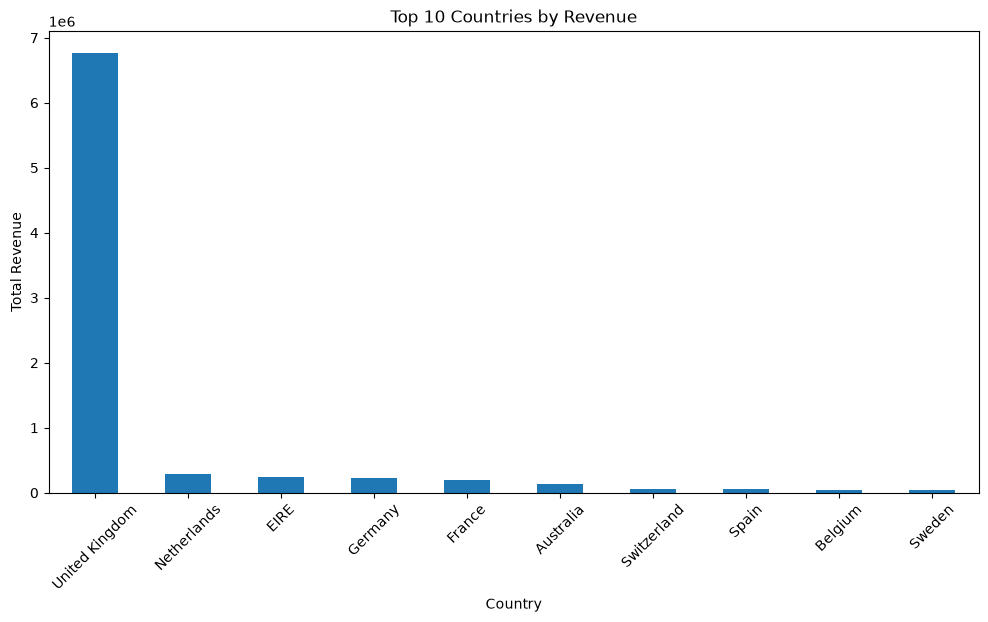

In [4]:
plt.figure(figsize=(12, 6))

country_sales.head(10).plot(kind="bar")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Country")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)

plt.show()

In [5]:
product_quantity = (
    df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

product_quantity.head(10)

Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     53215
JUMBO BAG RED RETROSPOT               45066
ASSORTED COLOUR BIRD ORNAMENT         35314
WHITE HANGING HEART T-LIGHT HOLDER    34147
PACK OF 72 RETROSPOT CAKE CASES       33409
POPCORN HOLDER                        30504
RABBIT NIGHT LIGHT                    27094
MINI PAINT SET VINTAGE                25880
PACK OF 12 LONDON TISSUES             25321
PACK OF 60 PINK PAISLEY CAKE CASES    24163
Name: Quantity, dtype: int64

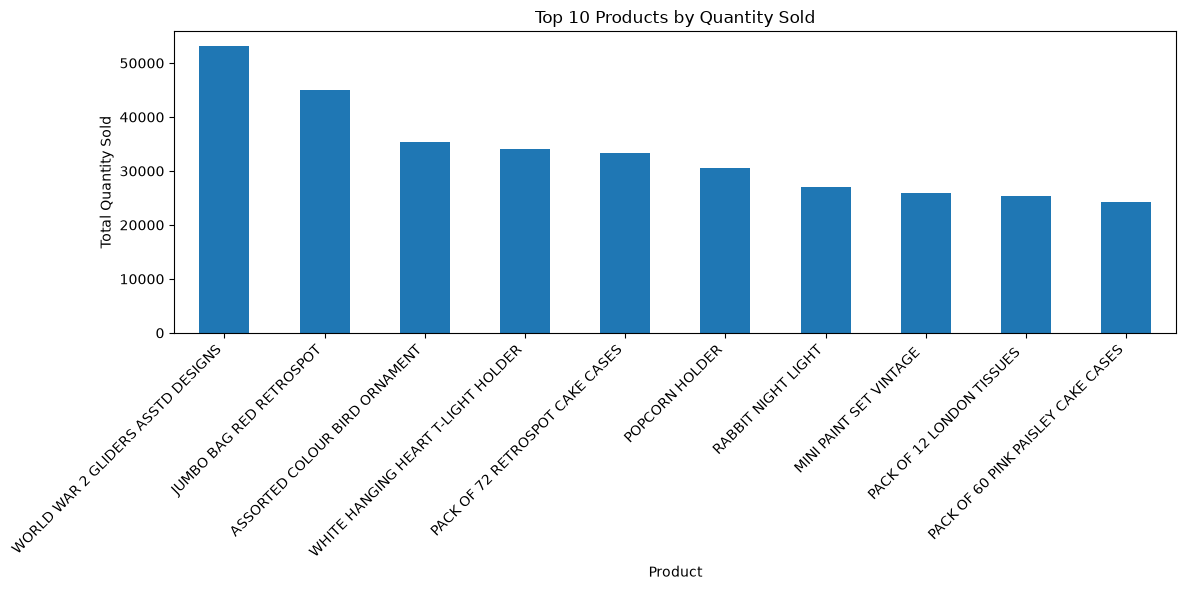

In [6]:
plt.figure(figsize=(12, 6))

product_quantity.head(10).plot(kind="bar")

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Product")
plt.ylabel("Total Quantity Sold")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [6]:
# Extract year and month from each invoice date
df["YearMonth"] = df["InvoiceDate"].dt.to_period("M").astype(str)

# Calculate total revenue for each month
monthly_sales = (
    df.groupby("YearMonth")["TotalSales"]
    .sum()
)

monthly_sales

YearMonth
2010-12     554604.020
2011-01     475074.380
2011-02     436546.150
2011-03     579964.610
2011-04     426047.851
2011-05     648251.080
2011-06     608013.160
2011-07     574238.481
2011-08     616368.000
2011-09     931440.372
2011-10     974603.590
2011-11    1132407.740
2011-12     342506.380
Name: TotalSales, dtype: float64

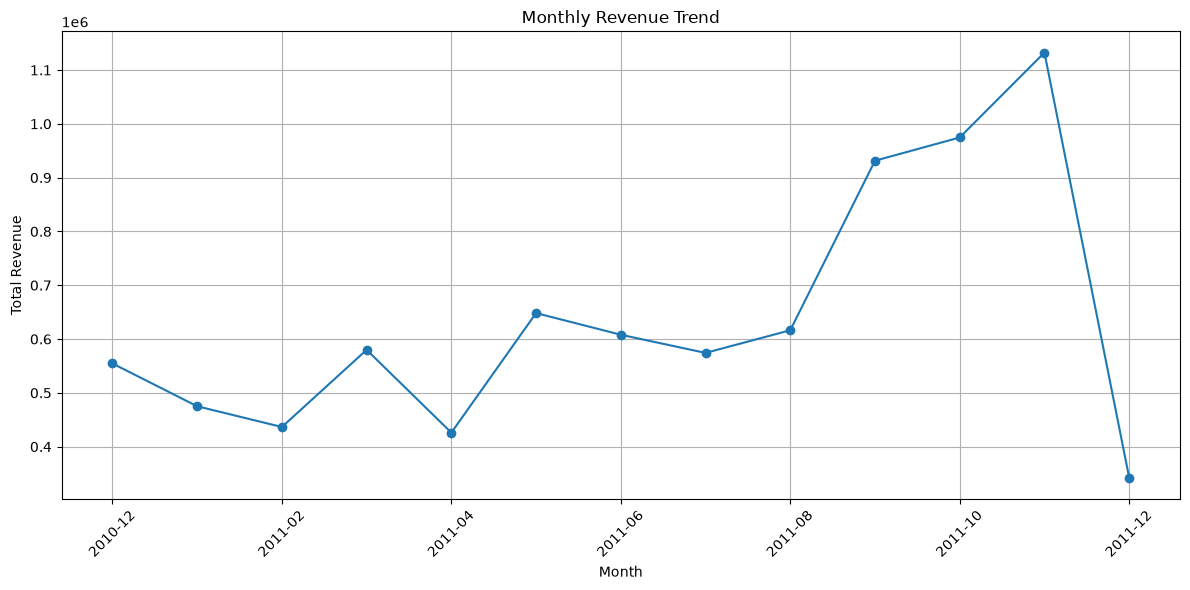

In [7]:
plt.figure(figsize=(12, 6))

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

In [9]:
daily_sales = (
    df.groupby(df["InvoiceDate"].dt.date)["TotalSales"]
    .sum()
)

daily_sales.head()

InvoiceDate
2010-12-01    46051.26
2010-12-02    45775.43
2010-12-03    22598.46
2010-12-05    31380.60
2010-12-06    30465.08
Name: TotalSales, dtype: float64

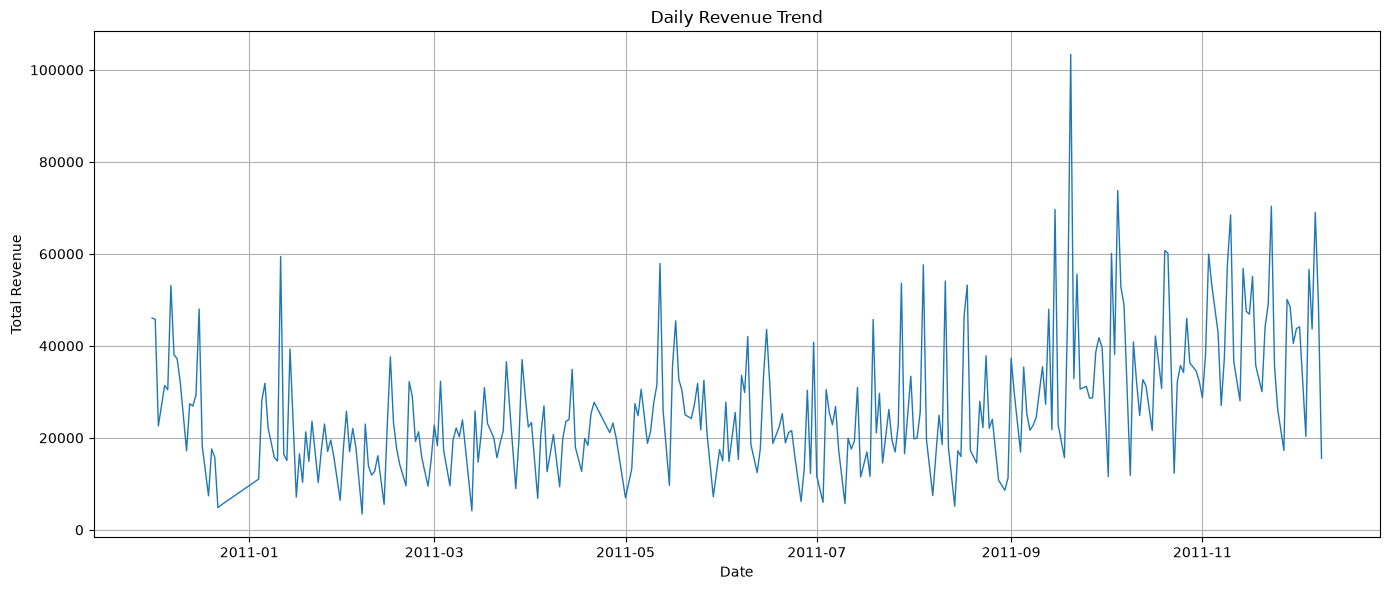

In [10]:
plt.figure(figsize=(14, 6))

daily_sales.plot(kind="line", linewidth=1)

plt.title("Daily Revenue Trend")
plt.xlabel("Date")
plt.ylabel("Total Revenue")
plt.grid(True)
plt.tight_layout()

plt.show()

In [11]:
daily_sales.idxmax(), daily_sales.max()

(datetime.date(2011, 9, 20), np.float64(103385.26))

In [12]:
customer_sales = (
    df.groupby("CustomerID")["TotalSales"]
    .sum()
    .sort_values(ascending=False)
)

customer_sales.head(10)

CustomerID
14646.0    279489.02
18102.0    256438.49
17450.0    187482.17
14911.0    132572.62
12415.0    123725.45
14156.0    113384.14
17511.0     88125.38
16684.0     65892.08
13694.0     62653.10
15311.0     59419.34
Name: TotalSales, dtype: float64

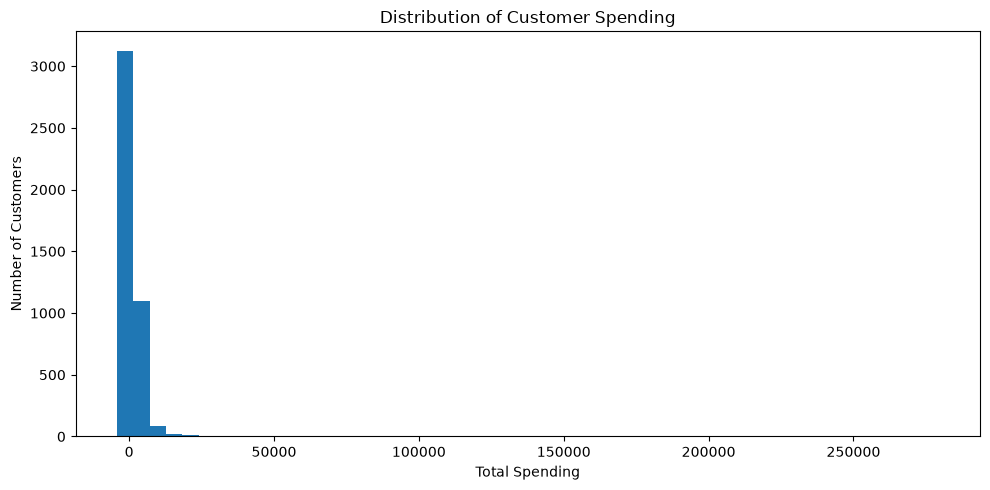

In [13]:
plt.figure(figsize=(10, 5))

customer_sales.plot(kind="hist", bins=50)

plt.title("Distribution of Customer Spending")
plt.xlabel("Total Spending")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.show()

In [14]:
customer_orders = df.groupby("CustomerID")["InvoiceNo"].nunique()

customer_orders.describe()

count    4372.000000
mean        5.075480
std         9.338754
min         1.000000
25%         1.000000
50%         3.000000
75%         5.000000
max       248.000000
Name: InvoiceNo, dtype: float64

In [15]:
customer_orders.sort_values(ascending=False).head(10)

CustomerID
14911.0    248
12748.0    224
17841.0    169
14606.0    128
15311.0    118
13089.0    118
12971.0     89
14527.0     86
13408.0     81
14646.0     77
Name: InvoiceNo, dtype: int64

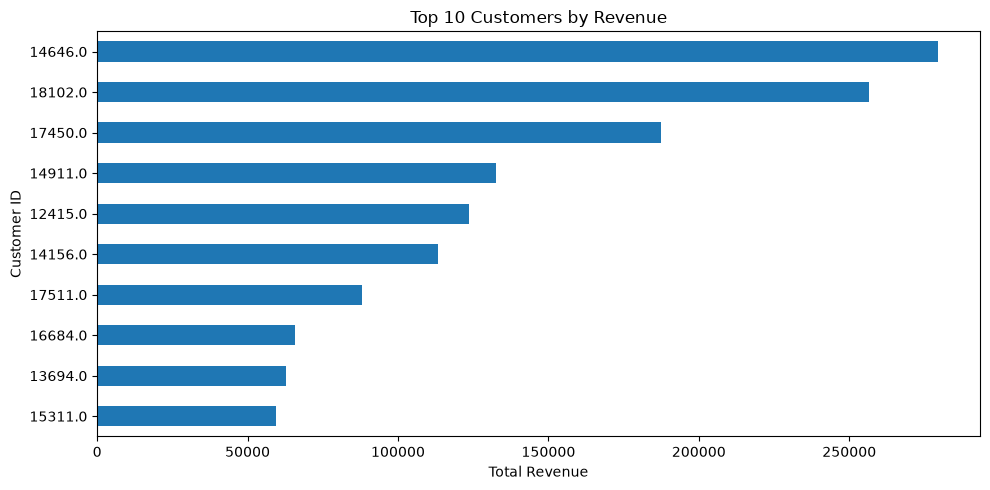

In [16]:
top_customers = customer_sales.head(10)

plt.figure(figsize=(10, 5))
top_customers.sort_values().plot(kind="barh")

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()

In [17]:
order_sales = df.groupby("InvoiceNo")["TotalSales"].sum()

order_sales.describe



<bound method NDFrame.describe of InvoiceNo
536365        139.12
536366         22.20
536367        278.73
536368         70.05
536369         17.85
             ...    
C581484   -168469.60
C581490       -32.53
C581499      -224.69
C581568       -54.75
C581569        -7.50
Name: TotalSales, Length: 22190, dtype: float64>

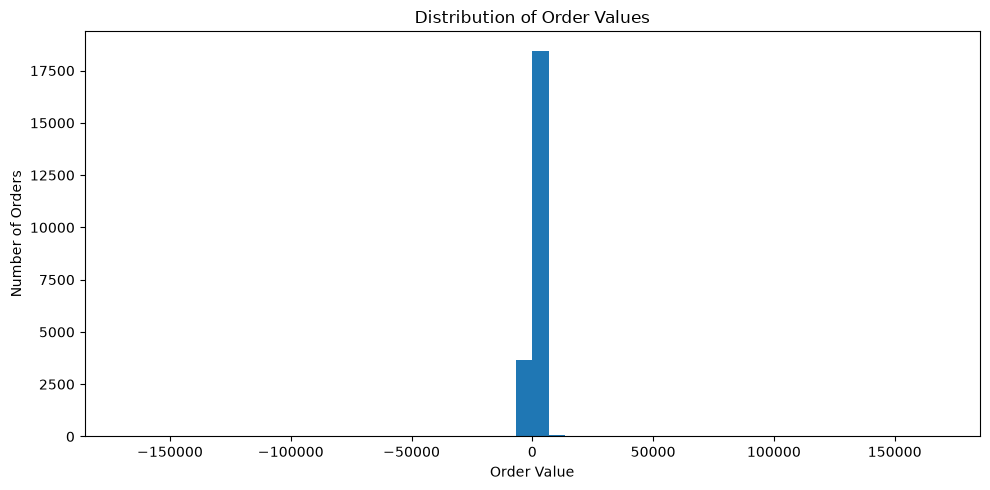

In [18]:
plt.figure(figsize=(10, 5))
order_sales.plot(kind="hist", bins=50)

plt.title("Distribution of Order Values")
plt.xlabel("Order Value")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

In [19]:
print("Total Revenue:", df["TotalSales"].sum())
print("Total Orders:", df["InvoiceNo"].nunique())
print("Unique Customers:", df["CustomerID"].nunique())
print("Average Order Value:", order_sales.mean())

Total Revenue: 8300065.813999999
Total Orders: 22190
Unique Customers: 4372
Average Order Value: 374.0453273546643


In [20]:
numeric_df = df[["Quantity", "UnitPrice", "TotalSales"]]

correlation = numeric_df.corr()
correlation

,Quantity,UnitPrice,TotalSales
Quantity,1.000000,-0.001238,0.916096
UnitPrice,-0.001238,1.000000,-0.129296
TotalSales,0.916096,-0.129296,1.000000


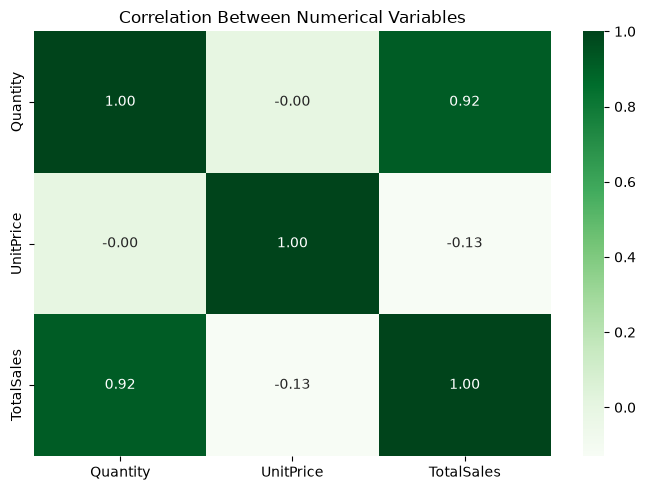

In [21]:
plt.figure(figsize=(7, 5))

sns.heatmap(correlation, annot=True, cmap="Greens", fmt=".2f")

plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()

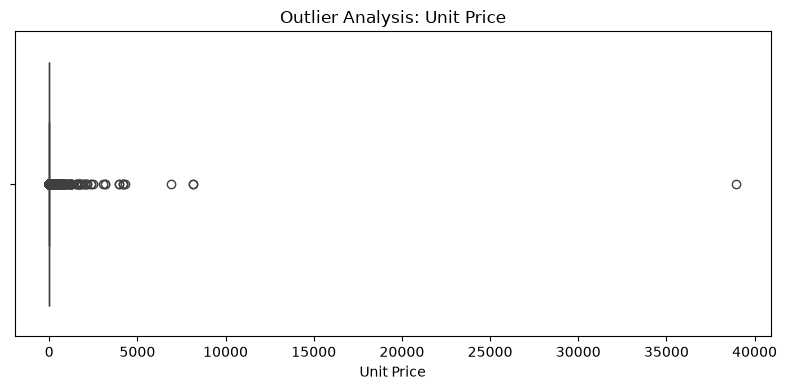

In [22]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df["UnitPrice"])

plt.title("Outlier Analysis: Unit Price")
plt.xlabel("Unit Price")
plt.tight_layout()
plt.show()

In [23]:
Q1 = df["UnitPrice"].quantile(0.25)
Q3 = df["UnitPrice"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["UnitPrice"] < lower_limit) |
    (df["UnitPrice"] > upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of outlier rows:", len(outliers))

Lower limit: -2.5
Upper limit: 7.5
Number of outlier rows: 36051


In [33]:
print("Total revenue:", df["TotalSales"].sum())
print("Total orders:", df["InvoiceNo"].nunique())
print("Unique customers:", df["CustomerID"].nunique())

print("\nTop 5 countries by revenue:")
print(country_sales.head(5))

print("\nTop 5 customers by revenue:")
print(customer_sales.head(5))

print("\nHighest-revenue month:")
print(monthly_sales.idxmax(), monthly_sales.max())

print("\nHighest-revenue day:")
print(daily_sales.idxmax(), daily_sales.max())

Total revenue: 8300065.813999999
Total orders: 22190
Unique customers: 4372

Top 5 countries by revenue:
Country
United Kingdom    6767873.394
Netherlands        284661.540
EIRE               250285.220
Germany            221698.210
France             196712.840
Name: TotalSales, dtype: float64

Top 5 customers by revenue:
CustomerID
14646.0    279489.02
18102.0    256438.49
17450.0    187482.17
14911.0    132572.62
12415.0    123725.45
Name: TotalSales, dtype: float64

Highest-revenue month:
2011-11 1132407.74

Highest-revenue day:
2011-09-20 103385.26


In [25]:
from pathlib import Path

figures_folder = Path("../visuals")
figures_folder.mkdir(parents=True, exist_ok=True)

print("Visuals folder is ready:", figures_folder)

Visuals folder is ready: ..\visuals


In [26]:

plt.savefig(figures_folder / "monthly_sales_trend.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

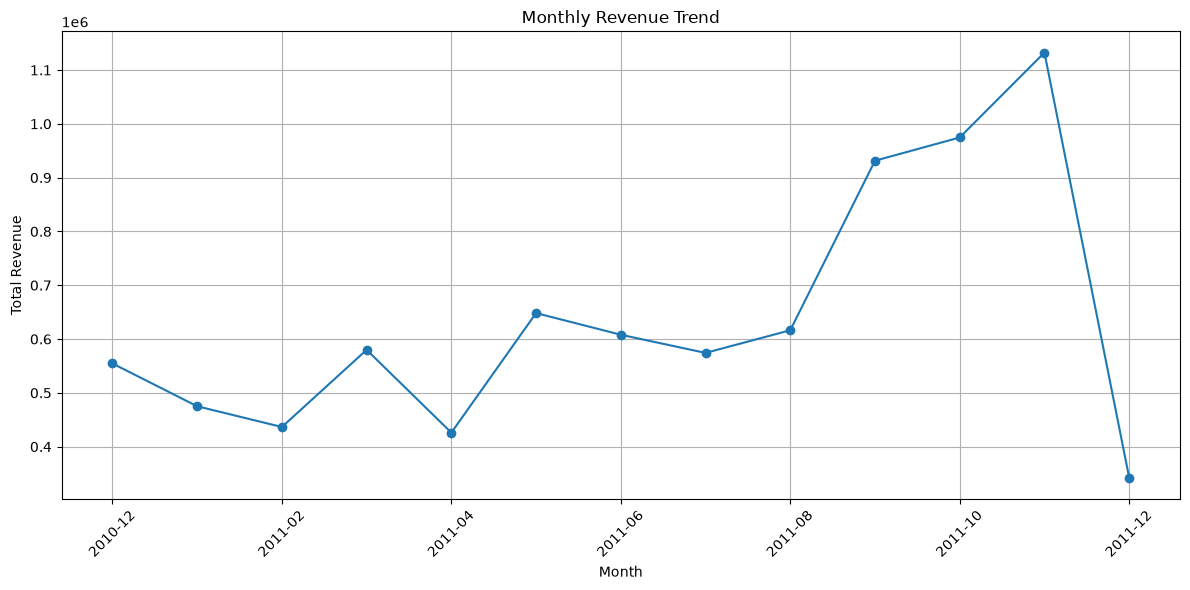

In [34]:
plt.figure(figsize=(12, 6))

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.savefig("../visuals/monthly_sales_trend.png",
            dpi=300, bbox_inches="tight")

plt.show()

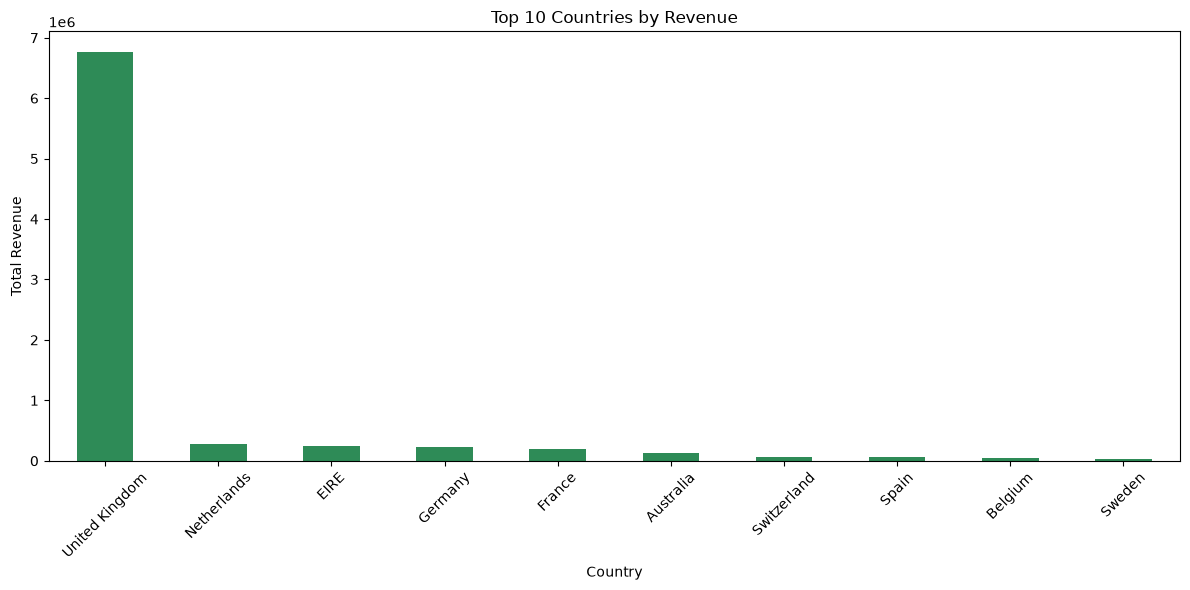

In [35]:
plt.figure(figsize=(12, 6))

country_sales.head(10).plot(kind="bar", color="seagreen")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Country")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("../visuals/top_10_countries.png",
            dpi=300, bbox_inches="tight")

plt.show()

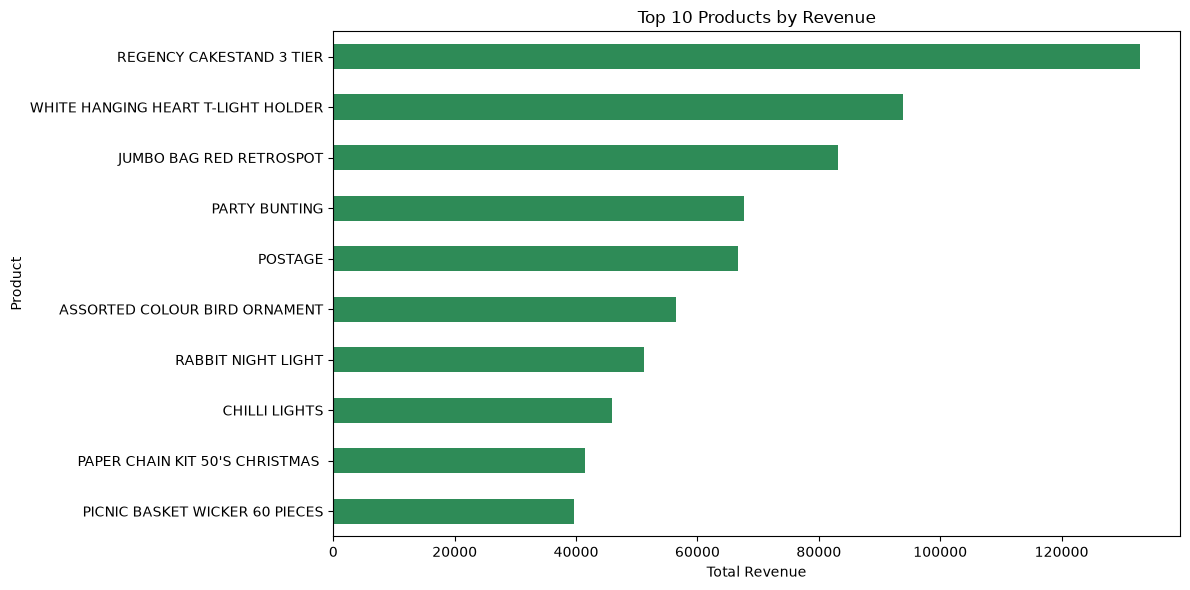

In [38]:
# Calculate total revenue for each product
product_sales = (
    df.groupby("Description")["TotalSales"]
    .sum()
    .sort_values(ascending=False)
)

# Plot top 10 products by revenue
plt.figure(figsize=(12, 6))

product_sales.head(10).sort_values().plot(
    kind="barh",
    color="seagreen"
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product")
plt.tight_layout()

plt.savefig(
    "../visuals/top_10_products.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

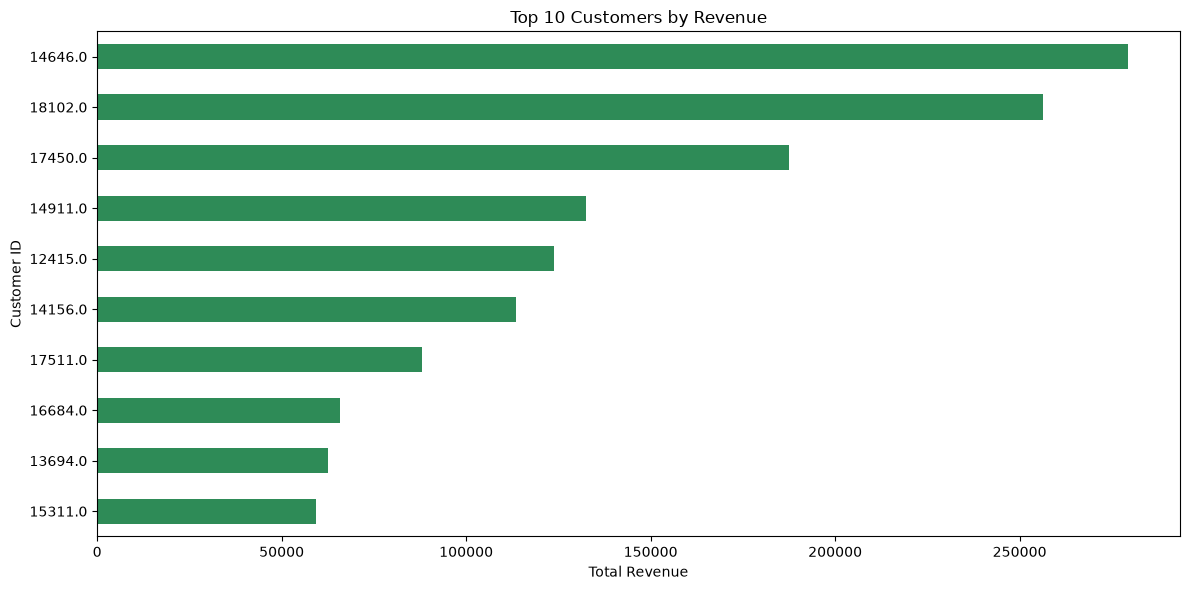

In [39]:
# Calculate total revenue per customer
customer_sales = (
    df.groupby("CustomerID")["TotalSales"]
    .sum()
    .sort_values(ascending=False)
)

# Plot top 10 customers
plt.figure(figsize=(12, 6))

customer_sales.head(10).sort_values().plot(
    kind="barh",
    color="seagreen"
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Customer ID")
plt.tight_layout()

plt.savefig(
    "../visuals/top_10_customers.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

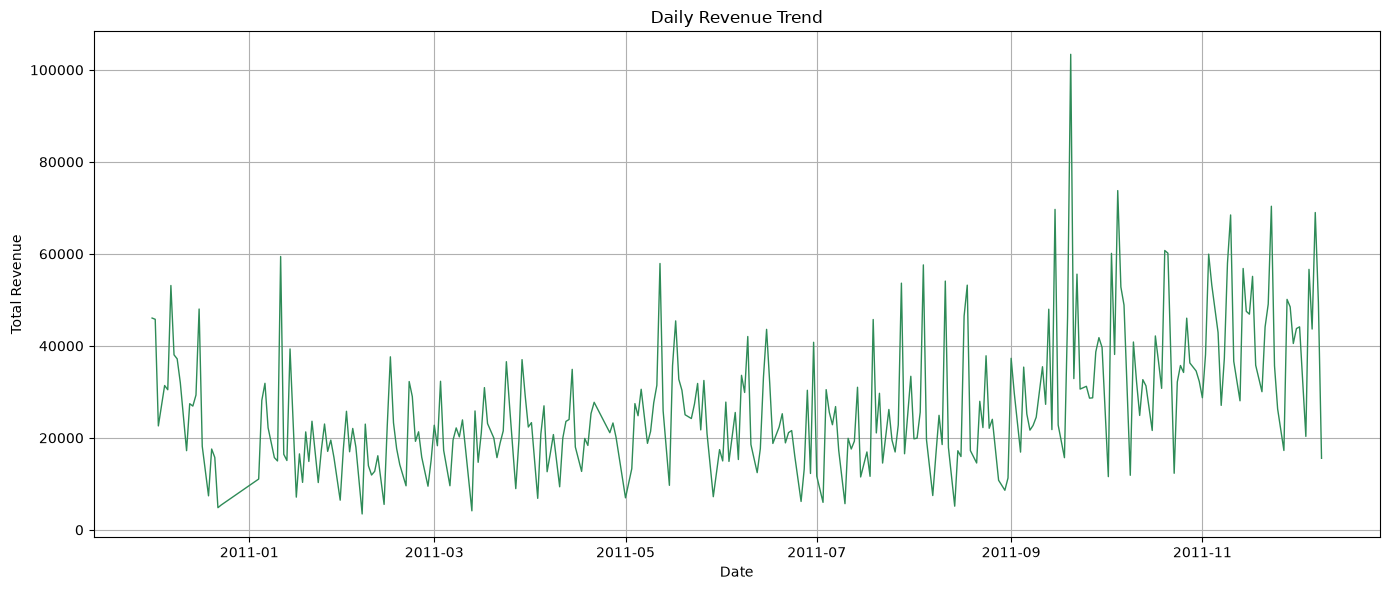

In [40]:
# Calculate daily revenue
daily_sales = (
    df.groupby(df["InvoiceDate"].dt.date)["TotalSales"]
    .sum()
)

# Plot daily revenue
plt.figure(figsize=(14, 6))

daily_sales.plot(kind="line", linewidth=1, color="seagreen")

plt.title("Daily Revenue Trend")
plt.xlabel("Date")
plt.ylabel("Total Revenue")
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "../visuals/daily_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

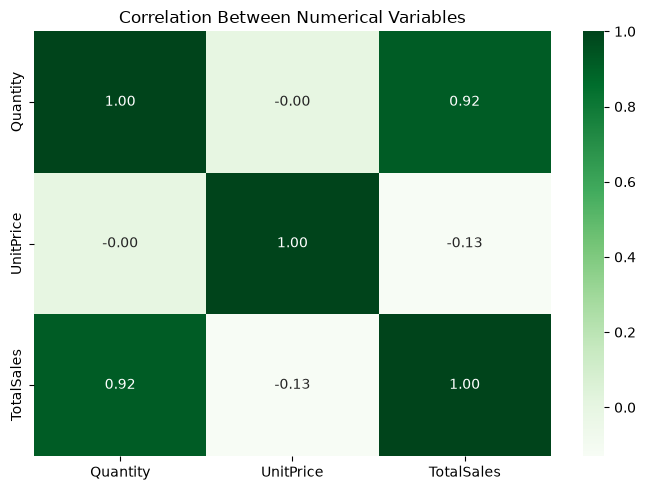

In [41]:
# Calculate correlations
numeric_df = df[["Quantity", "UnitPrice", "TotalSales"]]
correlation = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="Greens",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Variables")
plt.tight_layout()

plt.savefig(
    "../visuals/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

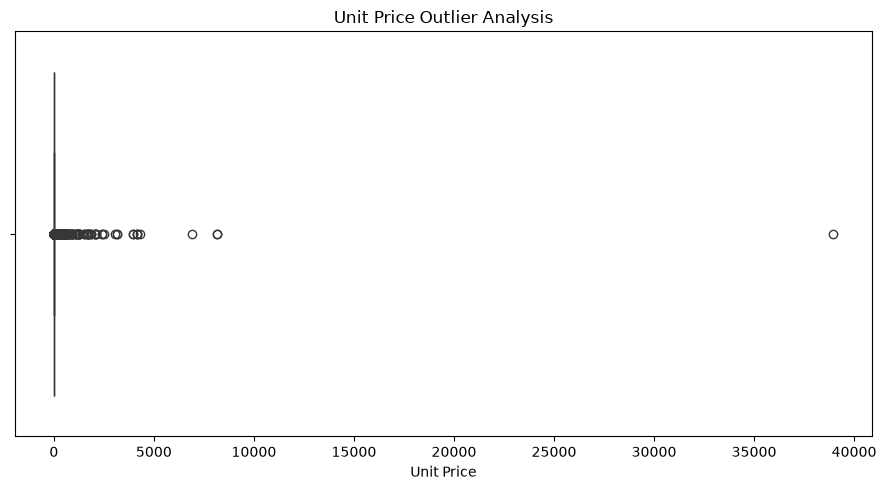

In [42]:
# Create the boxplot
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="UnitPrice", color="seagreen")

plt.title("Unit Price Outlier Analysis")
plt.xlabel("Unit Price")
plt.tight_layout()

# Save the chart
plt.savefig(
    "../visuals/unit_price_outliers.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()